# 19 · Generative Adversarial Networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/19-gan/19_gan.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-19-gan.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 19](https://github.com/anuxlab/deep-learning-systems/wiki/Module-19) |
| **Level** | Advanced |
| **Typical CPU runtime** | ~2–3 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 03, 07, 08 |

## What you will do

- Derive the optimal discriminator $D^*=p_d/(p_d+p_g)$ and verify it numerically with a trained discriminator.
- Show the saturating-loss gradient problem and the non-saturating fix.
- Train GANs on a 2-D 8-Gaussians ring; measure mode coverage, quality and MMD; compare saturating, non-saturating and WGAN-GP variants and quantify seed variance.
- Train WGAN-GP and compare; compute simple generative-model metrics (coverage, high-quality rate, MMD).

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

18:16:27 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43926876618
          commit: 30206410b37c093a0d326d94f81e5fd7c94a76ce


## 1 · The minimax game and the optimal discriminator
$$\min_G\max_D\ V(D,G)=\mathbb E_{x\sim p_d}[\log D(x)]+\mathbb E_{z}[\log(1-D(G(z)))].$$
For a *fixed* $G$ the optimal discriminator is $D^*(x)=\frac{p_d(x)}{p_d(x)+p_g(x)}$, and plugging it in gives $V(D^*,G)=-\log4+2\,\mathrm{JS}(p_d\|p_g)$: the generator minimises the Jensen–Shannon divergence. We **verify numerically** in 1-D: $p_d=\mathcal N(0,1)$, $p_g=\mathcal N(2,1)$ — train a discriminator by BCE and compare it with the analytic $D^*$; then check $V(D^*,G)$ against the JS formula.

18:16:31 | INFO | figure saved -> figures/optimal_discriminator.png


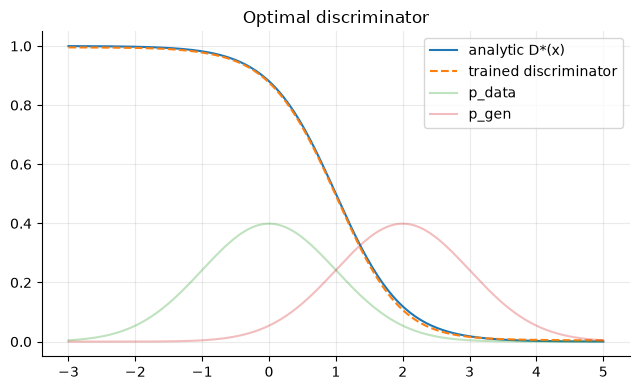

max |D* - D_hat| on [-2,4]: 0.012
  ✅ trained discriminator ≈ analytic D* = p_d/(p_d+p_g)
JS = 0.3368   V(D*,G) = -0.7126   -log4 + 2JS = -0.7126
  ✅ V(D*,G) = −log 4 + 2·JS(p_d‖p_g)


In [2]:
from scipy import stats
pd_, pg_ = stats.norm(0, 1), stats.norm(2, 1)
torch.manual_seed(0); rng = np.random.default_rng(0)
Dnet = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1)); o = torch.optim.Adam(Dnet.parameters(), 3e-3)
for it in range(1500):
    xr = torch.tensor(rng.normal(0, 1, (256, 1)), dtype=torch.float32); xg = torch.tensor(rng.normal(2, 1, (256, 1)), dtype=torch.float32)
    loss = F.binary_cross_entropy_with_logits(Dnet(xr), torch.ones(256, 1)) + F.binary_cross_entropy_with_logits(Dnet(xg), torch.zeros(256, 1)); o.zero_grad(); loss.backward(); o.step()
xs = np.linspace(-3, 5, 200); dstar = pd_.pdf(xs) / (pd_.pdf(xs) + pg_.pdf(xs))
with torch.no_grad(): dhat = torch.sigmoid(Dnet(torch.tensor(xs[:, None], dtype=torch.float32))).squeeze().numpy()
plt.plot(xs, dstar, label="analytic D*(x)"); plt.plot(xs, dhat, "--", label="trained discriminator"); plt.plot(xs, pd_.pdf(xs), alpha=.3, label="p_data"); plt.plot(xs, pg_.pdf(xs), alpha=.3, label="p_gen"); plt.legend(); plt.title("Optimal discriminator"); show("optimal_discriminator")
err = np.abs(dstar - dhat)[(xs > -2) & (xs < 4)].max(); print("max |D* - D_hat| on [-2,4]:", round(err, 3)); check(err < .08, "trained discriminator ≈ analytic D* = p_d/(p_d+p_g)")
# V(D*,G) = -log4 + 2 JS
grid = np.linspace(-10, 12, 200001); dx = grid[1] - grid[0]; p, q = pd_.pdf(grid), pg_.pdf(grid); m = (p + q) / 2
js = .5 * np.sum(p * np.log(p / m + 1e-300)) * dx + .5 * np.sum(q * np.log(q / m + 1e-300)) * dx; V = np.sum(p * np.log(p / (p + q))) * dx + np.sum(q * np.log(q / (p + q))) * dx
print(f"JS = {js:.4f}   V(D*,G) = {V:.4f}   -log4 + 2JS = {-np.log(4) + 2*js:.4f}"); check(abs(V - (-np.log(4) + 2 * js)) < 1e-4, "V(D*,G) = −log 4 + 2·JS(p_d‖p_g)")
METRICS["js_divergence_example"] = js

## 2 · Saturating vs non-saturating generator loss
Early in training $D$ easily rejects fakes: $D(G(z))\approx0$. The original generator loss $\log(1-D(G(z)))$ is then **flat** (gradient ≈ 0), so $G$ learns nothing. The non-saturating alternative $-\log D(G(z))$ has a strong gradient exactly there. With $D=\sigma(a)$, $\partial\log(1-\sigma(a))/\partial a=-\sigma(a)$ vs $\partial(-\log\sigma(a))/\partial a=-(1-\sigma(a))$.

18:16:31 | INFO | figure saved -> figures/saturation.png


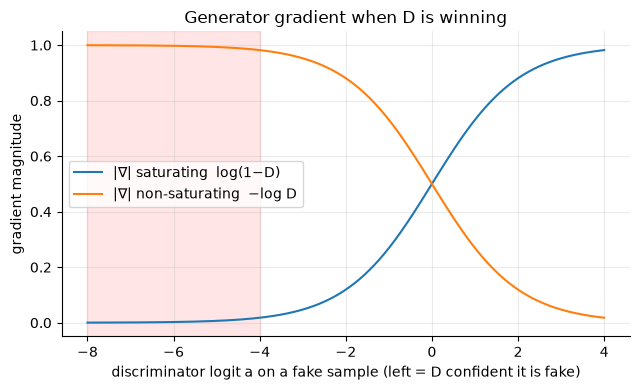

at logit -7.7: saturating |grad|=0.00045  non-saturating |grad|=1.000
  ✅ when D is confident, the non-saturating loss gives >100× larger gradient


In [3]:
a_ = torch.linspace(-8, 4, 400, requires_grad=True); sat = torch.log(1 - torch.sigmoid(a_) + 1e-12); nonsat = -torch.log(torch.sigmoid(a_) + 1e-12)
g_sat, = torch.autograd.grad(sat.sum(), a_, retain_graph=True); g_non, = torch.autograd.grad(nonsat.sum(), a_)
plt.plot(a_.detach(), g_sat.abs().detach(), label="|∇| saturating  log(1−D)"); plt.plot(a_.detach(), g_non.abs().detach(), label="|∇| non-saturating  −log D"); plt.axvspan(-8, -4, alpha=.1, color="r"); plt.xlabel("discriminator logit a on a fake sample (left = D confident it is fake)"); plt.ylabel("gradient magnitude"); plt.legend(); plt.title("Generator gradient when D is winning"); show("saturation")
i = 10; print(f"at logit {a_[i].item():.1f}: saturating |grad|={g_sat[i].abs():.5f}  non-saturating |grad|={g_non[i].abs():.3f}"); check(g_non[i].abs() > 100 * g_sat[i].abs(), "when D is confident, the non-saturating loss gives >100× larger gradient")

## 3 · 2-D toy problem: a ring of 8 Gaussians
A classic stress test for **mode collapse**. Data = 8 Gaussians (σ=0.05) on a circle of radius 2. A good generator covers all 8 modes. We define metrics: **mode coverage** (how many modes receive ≥ 1% of the samples within 3σ-ish), **high-quality rate** (fraction of samples within 0.2 of some mode centre) and an **MMD** between generated and real samples (RBF kernel).

real data: high-quality 0.9995 coverage 8
  ✅ metric sanity: real data has full coverage and quality


18:16:31 | INFO | figure saved -> figures/target_ring.png


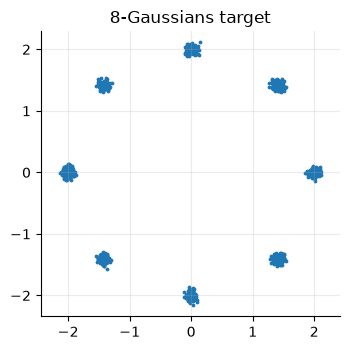

GAN builders ready


In [4]:
centers = np.array([[2 * np.cos(t), 2 * np.sin(t)] for t in np.linspace(0, 2 * np.pi, 9)[:-1]])
def real_batch(n, rng=np.random.default_rng(0)): c = centers[rng.integers(0, 8, n)]; return torch.tensor(c + .05 * rng.normal(size=(n, 2)), dtype=torch.float32)
def metrics(samples):
    s = samples.detach().numpy(); d = np.linalg.norm(s[:, None] - centers[None], axis=2); near = d.min(1); mode = d.argmin(1)
    hq = (near < .2).mean(); cov = sum(((mode == k) & (near < .2)).mean() > .01 for k in range(8)); return hq, cov
def mmd(x, y, bw=.5):
    k = lambda a, b: torch.exp(-torch.cdist(a, b) ** 2 / (2 * bw ** 2)).mean(); return (k(x, x) + k(y, y) - 2 * k(x, y)).item()
hq, cov = metrics(real_batch(2000, np.random.default_rng(1))); print("real data: high-quality", hq, "coverage", cov); check(cov == 8 and hq > .99, "metric sanity: real data has full coverage and quality")
fig = plt.figure(figsize=(3.6, 3.6)); plt.scatter(*real_batch(1000).T, s=3); plt.title("8-Gaussians target"); plt.axis("equal"); show("target_ring")
G = lambda: nn.Sequential(nn.Linear(2, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2))
Dn = lambda: nn.Sequential(nn.Linear(2, 128), nn.LeakyReLU(.2), nn.Linear(128, 128), nn.LeakyReLU(.2), nn.Linear(128, 1))
def train_gan(kind="nonsat", steps=3000, seed=0, d_steps=1, lr=1e-3, gp_w=10.):
    torch.manual_seed(seed); g, d = G(), Dn(); b1 = .5 if kind != "wgan-gp" else 0.0
    og, od = torch.optim.Adam(g.parameters(), lr, betas=(b1, .9)), torch.optim.Adam(d.parameters(), lr, betas=(b1, .9)); log_ = []
    for it in range(steps):
        for _ in range(d_steps if kind != "wgan-gp" else 5):
            xr = real_batch(128, np.random.default_rng(seed * 100000 + it * 7 + _)); xf = g(torch.randn(128, 2)).detach()
            if kind == "wgan-gp":
                eps = torch.rand(128, 1); xh = (eps * xr + (1 - eps) * xf).requires_grad_(); gr = torch.autograd.grad(d(xh).sum(), xh, create_graph=True)[0]
                ld = d(xf).mean() - d(xr).mean() + gp_w * ((gr.norm(dim=1) - 1) ** 2).mean()
            else: ld = F.binary_cross_entropy_with_logits(d(xr), torch.ones(128, 1)) + F.binary_cross_entropy_with_logits(d(xf), torch.zeros(128, 1))
            od.zero_grad(); ld.backward(); od.step()
        zf = g(torch.randn(128, 2)); lg = -d(zf).mean() if kind == "wgan-gp" else (F.binary_cross_entropy_with_logits(d(zf), torch.ones(128, 1)) if kind == "nonsat" else -F.binary_cross_entropy_with_logits(d(zf), torch.zeros(128, 1)))
        og.zero_grad(); lg.backward(); og.step()
        if it % 500 == 0 or it == steps - 1:
            with torch.no_grad(): s = g(torch.randn(2000, 2))
            hq, cv = metrics(s); log_.append((it, hq, cv, mmd(s[:1000], real_batch(1000, np.random.default_rng(5)))))
    return g, np.array(log_)
print("GAN builders ready")

saturating  final: high-quality 0.90  modes covered 8/8  MMD 0.0014


nonsat      final: high-quality 0.90  modes covered 8/8  MMD 0.0048


wgan-gp     final: high-quality 0.11  modes covered 5/8  MMD 0.0571
18:17:29 | INFO | gan_training took 57.26s


18:17:29 | INFO | figure saved -> figures/gan_ring_samples.png


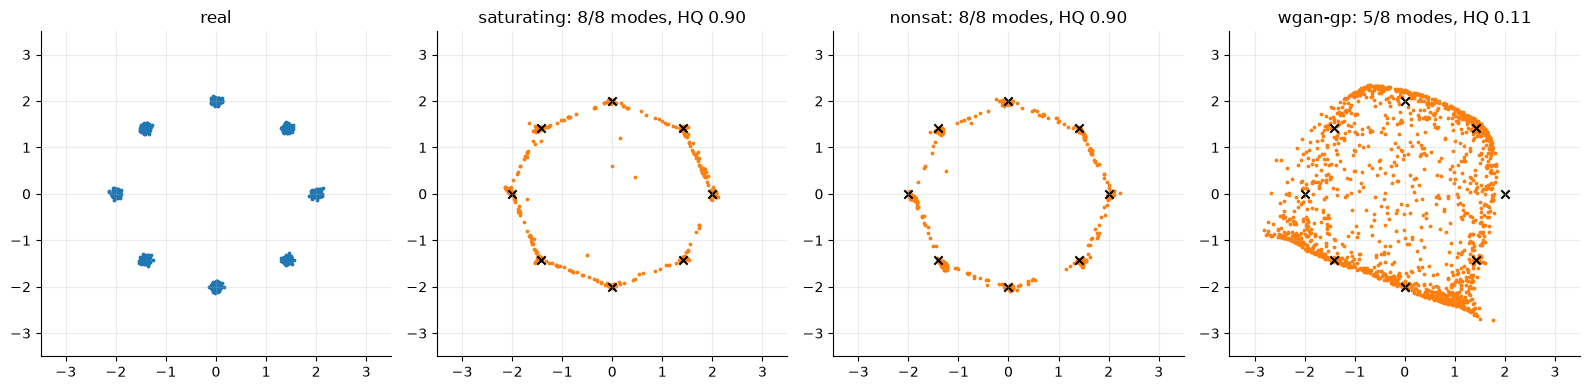

18:17:30 | INFO | figure saved -> figures/gan_training_curves.png


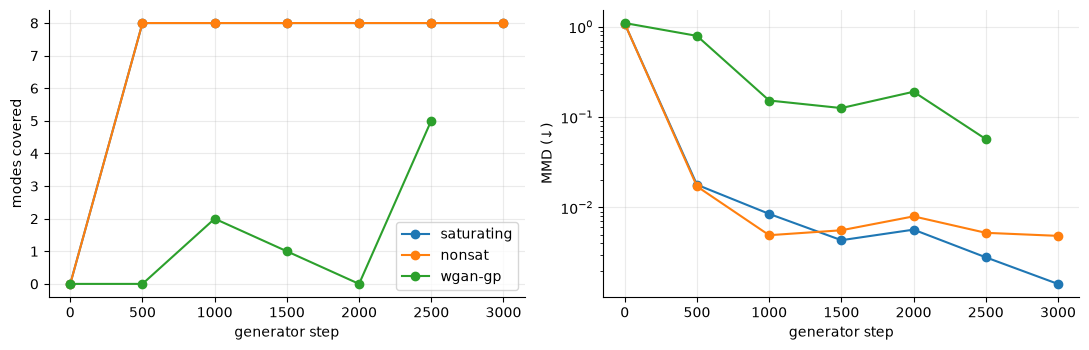

  ✅ at least one GAN variant covers ≥ 6 of 8 modes
  ✅ all generators beat a trivial baseline in MMD
  ✅ WGAN-GP is still improving: its MMD at the end is below its MMD at step 0


In [5]:
runs = {}
with timer("gan_training"):
    for kind in ["saturating", "nonsat", "wgan-gp"]:
        g, lg_ = train_gan(kind, steps=3000, lr=1e-3) if kind != "wgan-gp" else train_gan(kind, steps=2500, lr=2e-4); runs[kind] = (g, lg_)
        print(f"{kind:11s} final: high-quality {lg_[-1,1]:.2f}  modes covered {int(lg_[-1,2])}/8  MMD {lg_[-1,3]:.4f}")
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].scatter(*real_batch(1000).T, s=3); ax[0].set_title("real")
for a_, (kind, (g, lg_)) in zip(ax[1:], runs.items()):
    with torch.no_grad(): s = g(torch.randn(1500, 2))
    a_.scatter(*s.T, s=3, c="C1"); a_.scatter(*centers.T, c="k", marker="x"); a_.set_title(f"{kind}: {int(lg_[-1,2])}/8 modes, HQ {lg_[-1,1]:.2f}")
for a_ in ax: a_.set_xlim(-3.5, 3.5); a_.set_ylim(-3.5, 3.5)
show("gan_ring_samples")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for kind, (g, lg_) in runs.items(): ax[0].plot(lg_[:, 0], lg_[:, 2], "o-", label=kind); ax[1].semilogy(lg_[:, 0], lg_[:, 3], "o-", label=kind)
ax[0].set_ylabel("modes covered"); ax[1].set_ylabel("MMD (↓)"); ax[0].legend(); ax[0].set_xlabel("generator step"); ax[1].set_xlabel("generator step"); show("gan_training_curves")
METRICS["gan_final"] = {k: dict(hq=v[1][-1, 1], modes=int(v[1][-1, 2]), mmd=v[1][-1, 3]) for k, v in runs.items()}
check(max(v[1][-1, 2] for v in runs.values()) >= 6, "at least one GAN variant covers ≥ 6 of 8 modes")
check(all(v[1][-1, 3] < .5 for v in runs.values()), "all generators beat a trivial baseline in MMD")
check(runs["wgan-gp"][1][-1, 3] < runs["wgan-gp"][1][0, 3], "WGAN-GP is still improving: its MMD at the end is below its MMD at step 0")

## 4 · Reading the results honestly
GAN training is **non-stationary and seed-dependent**, and results at a tiny CPU budget need careful reading. On this *easy* 2-D task the standard (saturating and non-saturating) GANs did **not** collapse. WGAN-GP — which trades speed for robustness (5 critic updates per generator update, small learning rate, a loss that correlates with sample quality because the Wasserstein distance does not saturate) — is still *improving* when we stop, so it looks worse here; its advantage appears on harder problems, longer runs, or when the discriminator would otherwise overpower the generator. We check that its MMD is decreasing, and then quantify seed variance for the non-saturating GAN with 3 seeds (short runs). We quantify seed variance for the non-saturating GAN with 3 seeds (short runs).

In [6]:
sv = []
with timer("gan_seed_variance"):
    for sd in range(3): g, lg_ = train_gan("nonsat", steps=1500, seed=sd + 10); sv.append((lg_[-1, 1], int(lg_[-1, 2]), lg_[-1, 3])); print(f"seed {sd}: HQ {sv[-1][0]:.2f}  modes {sv[-1][1]}/8  MMD {sv[-1][2]:.4f}")
print("modes covered across seeds:", [s[1] for s in sv], "→ spread shows why single-run GAN claims are weak evidence"); METRICS["gan_seed_modes"] = [s[1] for s in sv]
check(len(sv) == 3, "three independent seeds completed")

seed 0: HQ 0.82  modes 8/8  MMD 0.0029


seed 1: HQ 0.79  modes 8/8  MMD 0.0080


seed 2: HQ 0.80  modes 8/8  MMD 0.0062
18:17:45 | INFO | gan_seed_variance took 14.62s


modes covered across seeds: [8, 8, 8] → spread shows why single-run GAN claims are weak evidence
  ✅ three independent seeds completed


In [7]:
save_metrics("19", METRICS)
log.info('notebook 19 finished OK')

18:17:45 | INFO | metrics saved -> metrics.json


18:17:45 | INFO | notebook 19 finished OK


## Wrap-up

## Exercises (do these next)

1. Add spectral normalisation to the discriminator (`torch.nn.utils.spectral_norm`) and re-run the non-saturating GAN.
2. Implement unrolled GAN or minibatch discrimination and see if coverage improves.
3. Train a *conditional* GAN on 2-D data (condition = mode index) and verify each condition generates its own mode.

## Where to read more

- Wiki chapter: [Module 19](https://github.com/anuxlab/deep-learning-systems/wiki/Module-19) (derivations, worked example, Q&A).
- Goodfellow et al. (2014); Arjovsky et al. (2017) WGAN; Gulrajani et al. (2017) WGAN-GP; Mescheder et al. (2018) *Which training methods for GANs do actually converge?*; Metz et al. (2017) unrolled GANs.